<a href="https://colab.research.google.com/github/sidd-coder1/CSL701-CE46_Machine-Learning-Lab/blob/main/Experiments/Experiment9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9


Name : Singh Siddharth Dharmendra

Batch :CE03


Roll Number :CE46






### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load dataset
dfp = pd.read_csv('/content/palmerpenguins_extended.csv')
display(dfp.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:
# Check for missing values
print("Missing values before preprocessing:\n", dfp.isnull().sum())

# Drop rows with missing values
dfp = dfp.dropna()

# Select Features and Target
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
# Use correct columns if named slightly differently in the dataset
# Map columns to correspond with standard names in the prompt
rename_dict = {
    'culmen_length_mm': 'bill_length_mm',
    'culmen_depth_mm': 'bill_depth_mm'
}
dfp = dfp.rename(columns=rename_dict)

# Filter features to those that actually exist
existing_features = [f for f in features if f in dfp.columns]
if len(existing_features) < 4:
    # Fallback to check other potential names
    alternatives = {'culmen_length_mm': 'bill_length_mm', 'culmen_depth_mm': 'bill_depth_mm'}
    for alt, standard in alternatives.items():
        if alt in dfp.columns and standard not in dfp.columns:
            dfp[standard] = dfp[alt]
            existing_features.append(standard)

X = dfp[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']]
y = dfp['species']

# Encode categorical targets
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nEncoded classes:", dict(zip(le.classes_, le.transform(le.classes_))))

Missing values before preprocessing:
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: int64

Encoded classes: {'Adelie': np.int64(0), 'Chinstrap': np.int64(1), 'Gentoo': np.int64(2)}


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:
# Split into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (2744, 4)
Testing set shape: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:
# Initialize and train CART model using Gini impurity
cart_model = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
cart_model.fit(X_train, y_train)

# Predict on test set
y_pred_cart = cart_model.predict(X_test)

# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Classifier Accuracy: 0.5671

Confusion Matrix:


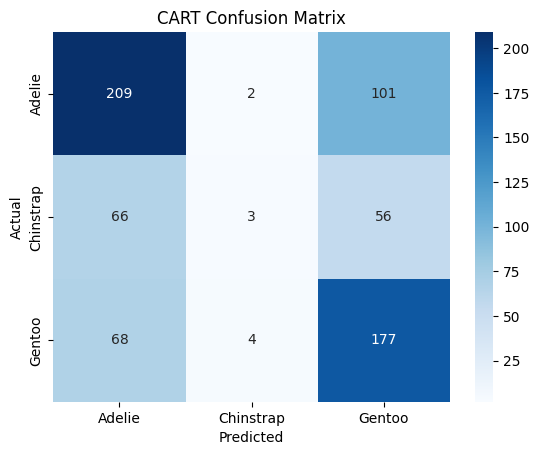


Classification Report:
              precision    recall  f1-score   support

      Adelie       0.61      0.67      0.64       312
   Chinstrap       0.33      0.02      0.04       125
      Gentoo       0.53      0.71      0.61       249

    accuracy                           0.57       686
   macro avg       0.49      0.47      0.43       686
weighted avg       0.53      0.57      0.52       686



In [ ]:
# Calculate performance metrics for CART model
cart_acc = accuracy_score(y_test, y_pred_cart)
print(f"CART Classifier Accuracy: {cart_acc:.4f}\n")

print("Confusion Matrix:")
cm_cart = confusion_matrix(y_test, y_pred_cart)
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CART Confusion Matrix')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


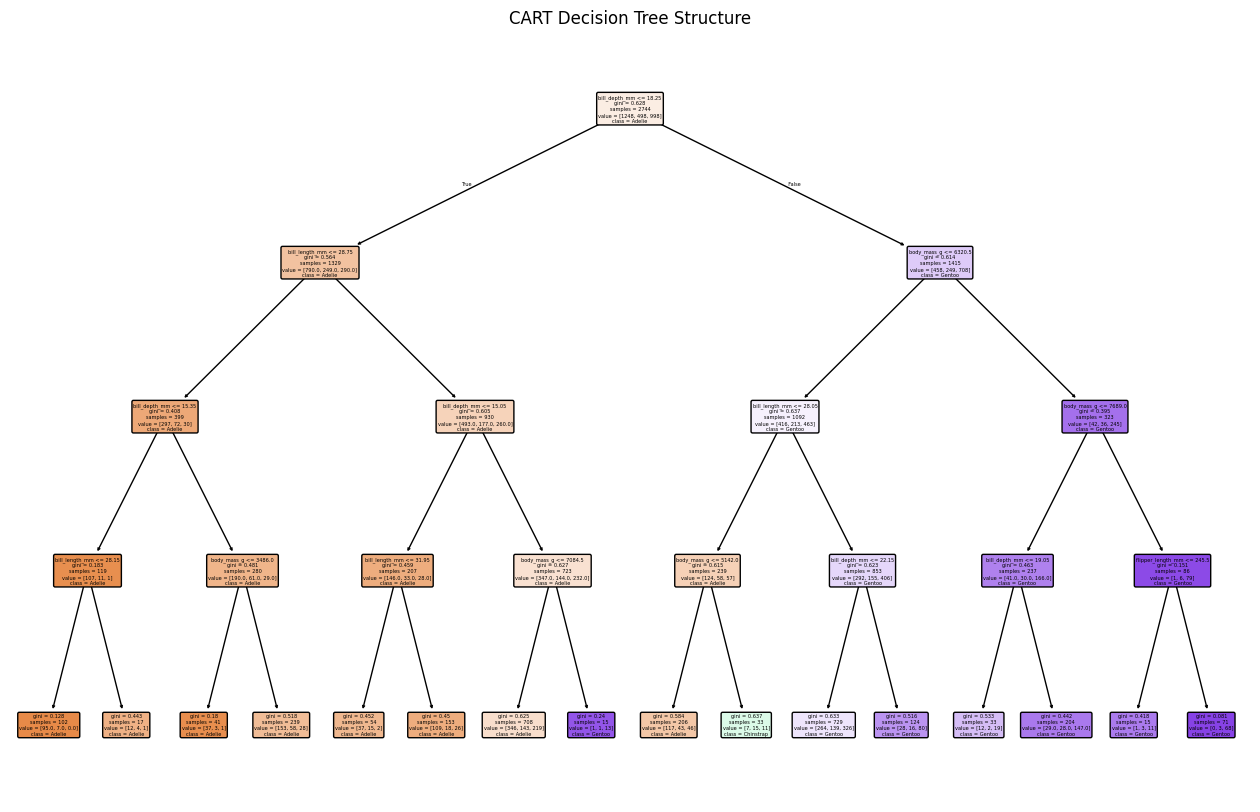

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


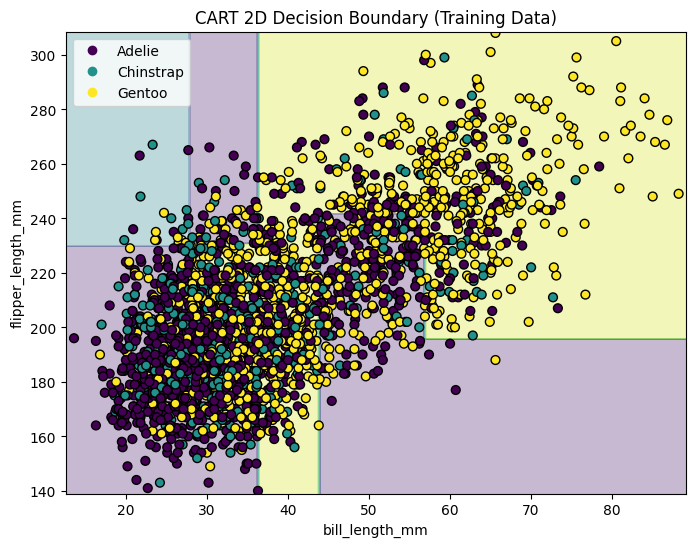

In [ ]:
# 1. Visualize tree structure
plt.figure(figsize=(16, 10))
plot_tree(cart_model, feature_names=X.columns, class_names=le.classes_, filled=True, rounded=True)
plt.title("CART Decision Tree Structure")
plt.show()

# 2. Select 2-D Features
X_2d = dfp[['bill_length_mm', 'flipper_length_mm']]
y_2d = y_encoded

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d, test_size=0.2, random_state=42, stratify=y_2d
)

# Train 2D Decision Tree Model
cart_2d = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
cart_2d.fit(X_train_2d, y_train_2d)

# Function to plot decision boundaries
def plot_decision_boundary(clf, X, y, title):
    x_min, x_max = X.iloc[:, 0].min() - 1, X.iloc[:, 0].max() + 1
    y_min, y_max = X.iloc[:, 1].min() - 1, X.iloc[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 0.5))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    scatter = plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y, cmap='viridis', edgecolor='k', s=40)
    plt.xlabel(X.columns[0])
    plt.ylabel(X.columns[1])
    plt.title(title)
    plt.legend(handles=scatter.legend_elements()[0], labels=list(le.classes_))

plt.figure(figsize=(8, 6))
plot_decision_boundary(cart_2d, X_train_2d, y_train_2d, "CART 2D Decision Boundary (Training Data)")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


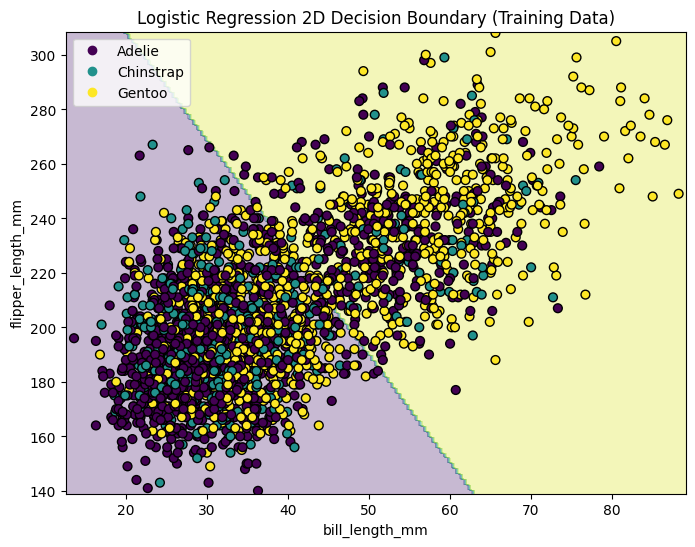

In [ ]:
# Train Logistic Regression Model on 2D Features
log_reg_2d = LogisticRegression(max_iter=1000, random_state=42)
log_reg_2d.fit(X_train_2d, y_train_2d)

plt.figure(figsize=(8, 6))
plot_decision_boundary(log_reg_2d, X_train_2d, y_train_2d, "Logistic Regression 2D Decision Boundary (Training Data)")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


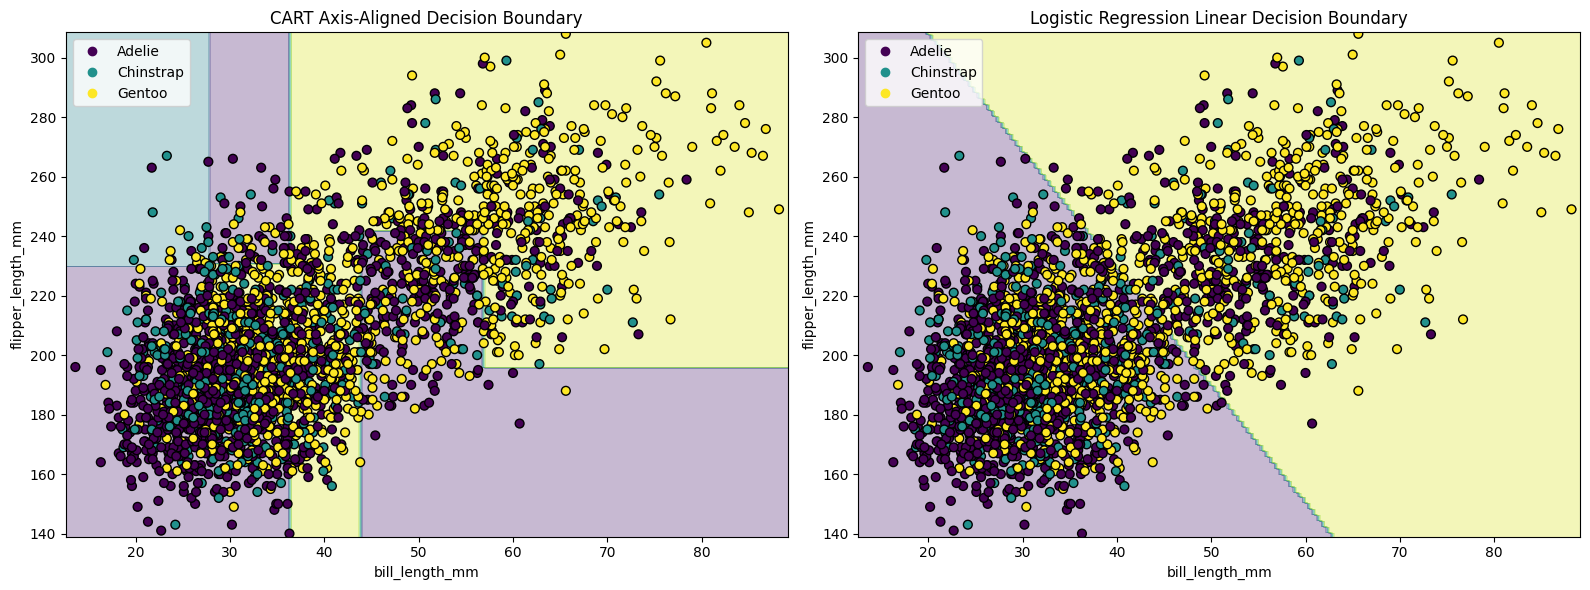

In [ ]:
# Side-by-side subplots of CART and Logistic Regression boundaries
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left subplot: CART
plt.subplot(1, 2, 1)
plot_decision_boundary(cart_2d, X_train_2d, y_train_2d, "CART Axis-Aligned Decision Boundary")

# Right subplot: Logistic Regression
plt.subplot(1, 2, 2)
plot_decision_boundary(log_reg_2d, X_train_2d, y_train_2d, "Logistic Regression Linear Decision Boundary")

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

In [ ]:
# Make predictions on test set with 2D models
y_pred_cart_2d = cart_2d.predict(X_test_2d)
y_pred_log_2d = log_reg_2d.predict(X_test_2d)

# Evaluation Metrics Comparison
print("========== CART (2D Features) ==========")
print(f"Accuracy: {accuracy_score(y_test_2d, y_pred_cart_2d):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_2d, y_pred_cart_2d, target_names=le.classes_))

print("\n========== Logistic Regression (2D Features) ==========")
print(f"Accuracy: {accuracy_score(y_test_2d, y_pred_log_2d):.4f}")
print("\nClassification Report:")
print(classification_report(y_test_2d, y_pred_log_2d, target_names=le.classes_))

========== CART (2D Features) ==========
Accuracy: 0.5131

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.54      0.62      0.57       312
   Chinstrap       0.33      0.01      0.02       125
      Gentoo       0.49      0.64      0.55       249

    accuracy                           0.51       686
   macro avg       0.45      0.42      0.38       686
weighted avg       0.48      0.51      0.46       686


========== Logistic Regression (2D Features) ==========
Accuracy: 0.5262

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weighted avg       0.44      0.53      0.47       686



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# **Conclusion**


The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.